<a href="https://colab.research.google.com/github/VizDataWorks/eCommerce_data_analysis/blob/main/notebooks/03_referral_program.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Revenue lost to the referral program

**Question:** What is the total revenue lost due to the referral program? Should we keep offering the discount?

**Short answer:** **\$21,325 net revenue lost** over 2024–2025, about **\$6 per referred customer**. **Keep it:** referred customers are almost as valuable as others (\$324 vs \$332 profit per active buyer).

**Business rules (from the brief)**
- **Referral:** 10% off a referred customer's first order, applied after any Black Friday discount (20%).
- **Shipping charged:** \$7.99 under \$50, \$4.99 from \$50 to \$99.99, free from \$100. **Carrier fee:** \$4.99 per order, paid by the company.

**Approach**
- Delivered orders only. First order = the buyer's earliest delivered order.
- **Revenue lost = referral discount − extra shipping it caused.** A discount can push an order into a higher shipping tier, so the customer pays more shipping, which offsets part of the discount.
- **Profit per order = item profit − discounts + shipping charged − carrier fee.**

## 1. Setup

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Get the project data from GitHub: no Google Drive or sign-in needed
REPO = "https://github.com/VizDataWorks/eCommerce_data_analysis.git"
!rm -rf repo
!git clone -q --depth 1 {REPO} repo

CLEAN = os.path.join("repo", "data", "clean")
pd.set_option("display.max_columns", 30, "display.width", 160)

# Business rules from the brief
REFERRAL_DISCOUNT = 0.10
BLACK_FRIDAY_DISCOUNT = 0.20
BLACK_FRIDAYS = pd.to_datetime(["2024-11-29", "2025-11-28"])   # add a date if the data covers more years
CARRIER_FEE = 4.99


def shipping_charged(item_total):
    # $7.99 under $50, $4.99 from $50 to $99.99, free from $100
    return np.select([item_total < 50, item_total < 100], [7.99, 4.99], 0.0)

## 2. Load data

In [2]:
customers = pd.read_csv(os.path.join(CLEAN, "customers.csv"),
                        usecols=["buyer_id", "is_referred"], dtype={"is_referred": "Int64"})
products = pd.read_csv(os.path.join(CLEAN, "products.csv"), usecols=["sku_id", "price", "profit_margin"])
sales = pd.read_csv(os.path.join(CLEAN, "sales.csv.gz"),
                    usecols=["order_id", "buyer_id", "sku_id", "quantity", "order_datetime", "is_revenue"],
                    parse_dates=["order_datetime"])   # order_datetime is the buyer's local time

## 3. Build one row per delivered order

Each order gets its list price, Black Friday discount, referral discount, shipping and profit.

In [3]:
lines = sales[sales.is_revenue & sales.quantity.notna()].merge(products, on="sku_id", how="left")
assert lines.price.notna().all(), "some sales lines have no matching product"
lines["list_revenue"] = lines.quantity * lines.price
lines["item_profit"] = lines.list_revenue * lines.profit_margin

orders = (lines.groupby("order_id")
               .agg(buyer_id=("buyer_id", "first"), order_time=("order_datetime", "min"),
                    list_revenue=("list_revenue", "sum"), item_profit=("item_profit", "sum"))
               .reset_index()
               .merge(customers, on="buyer_id", how="left"))

# Black Friday first: 20% off, by the buyer's local date
is_black_friday = orders.order_time.dt.normalize().isin(BLACK_FRIDAYS)
orders["black_friday_discount"] = orders.list_revenue.where(is_black_friday, 0) * BLACK_FRIDAY_DISCOUNT
orders["pre_referral_total"] = orders.list_revenue - orders.black_friday_discount

# Then 10% off a referred buyer's first delivered order (ties broken by order_id)
first_orders = (orders.dropna(subset=["buyer_id", "order_time"])
                      .sort_values(["order_time", "order_id"])
                      .drop_duplicates("buyer_id").order_id)
orders["is_referral_order"] = orders.order_id.isin(first_orders) & orders.is_referred.eq(1).fillna(False)
orders["referral_discount"] = orders.pre_referral_total.where(orders.is_referral_order, 0) * REFERRAL_DISCOUNT
orders["item_total"] = orders.pre_referral_total - orders.referral_discount

# Shipping with and without the referral discount, then revenue and profit
orders["shipping"] = shipping_charged(orders.item_total)
orders["shipping_without_referral"] = shipping_charged(orders.pre_referral_total)
orders["total_revenue"] = orders.item_total + orders.shipping
orders["profit"] = (orders.item_profit - orders.black_friday_discount - orders.referral_discount
                    + orders.shipping - CARRIER_FEE)

print(f"{len(orders):,} delivered orders; {orders.is_referral_order.sum():,} were a referred buyer's first order")

235,228 delivered orders; 3,563 were a referred buyer's first order


## 4. Revenue lost to the referral discount

In [4]:
ref = orders[orders.is_referral_order]
discount = ref.referral_discount.sum()
extra_shipping = (ref.shipping - ref.shipping_without_referral).sum()

pd.Series({
    "Referred buyers' first orders": f"{len(ref):,}",
    "Referral discount given": f"${discount:,.2f}",
    "Less: extra shipping the discount caused": f"${extra_shipping:,.2f}",
    "Net revenue lost": f"${discount - extra_shipping:,.2f}",
    "Average discount per referred customer": f"${ref.referral_discount.mean():.2f}",
}).to_frame("2024–2025")

,2024–2025
Referred buyers' first orders,"3,563"
Referral discount given,"$22,188.76"
Less: extra shipping the discount caused,$863.37
Net revenue lost,"$21,325.39"
Average discount per referred customer,$6.23


## 5. Do referred first orders still make money?

Small orders are where a discount hurts most: they also pay the highest shipping tier and still carry the $4.99 carrier fee.

In [5]:
order_size = pd.cut(ref.pre_referral_total, [0, 50, 100, np.inf], right=False,
                    labels=["Under $50", "$50–99.99", "$100 and up"])

by_size = ref.groupby(order_size, observed=True).agg(
    orders=("order_id", "size"),
    referral_discount=("referral_discount", "sum"),
    avg_profit=("profit", "mean"),
    losing_money=("profit", lambda p: (p < 0).mean()),
)
by_size.loc["All referred first orders"] = [len(ref), discount, ref.profit.mean(), (ref.profit < 0).mean()]

by_size.rename_axis("Order size (before referral discount)").style.format(
    {"orders": "{:,.0f}", "referral_discount": "${:,.0f}", "avg_profit": "${:.2f}", "losing_money": "{:.1%}"})

,orders,referral_discount,avg_profit,losing_money
Order size (before referral discount),,,,
Under $50,"2,273","$4,806",$8.60,3.4%
$50–99.99,761,"$5,202",$16.13,8.1%
$100 and up,529,"$12,181",$88.98,6.2%
All referred first orders,"3,563","$22,189",$22.14,4.9%


## 6. Are referred customers worth it?

Compares every customer by referral status. **Active** = at least one delivered order in 2024–2025. Revenue and profit include discounts, shipping and the carrier fee.

In [6]:
buyer_value = orders.groupby("buyer_id").agg(
    orders=("order_id", "size"), revenue=("total_revenue", "sum"), profit=("profit", "sum"))
cust = customers.join(buyer_value, on="buyer_id")
cohort = cust.is_referred.map({1: "Referred", 0: "Not referred"}).fillna("Unknown")

# Per-buyer averages skip customers with no orders, so they're per *active* buyer
cohorts = cust.groupby(cohort).agg(
    customers=("buyer_id", "size"),
    active_pct=("orders", lambda o: o.notna().mean()),
    orders_per_active_buyer=("orders", "mean"),
    revenue_per_active_buyer=("revenue", "mean"),
    profit_per_active_buyer=("profit", "mean"),
).loc[["Referred", "Not referred", "Unknown"]].rename_axis("Cohort")
cohorts.insert(3, "avg_order_value", cohorts.revenue_per_active_buyer / cohorts.orders_per_active_buyer)

cohorts.style.format({"customers": "{:,}", "active_pct": "{:.1%}", "orders_per_active_buyer": "{:.2f}",
                      "avg_order_value": "${:.2f}", "revenue_per_active_buyer": "${:,.2f}",
                      "profit_per_active_buyer": "${:,.2f}"})

,customers,active_pct,orders_per_active_buyer,avg_order_value,revenue_per_active_buyer,profit_per_active_buyer
Cohort,,,,,,
Referred,"6,984",51.0%,9.46,$82.86,$783.62,$323.61
Not referred,"40,043",50.0%,9.39,$85.25,$800.56,$332.12
Unknown,473,45.2%,9.09,$77.22,$702.18,$286.95


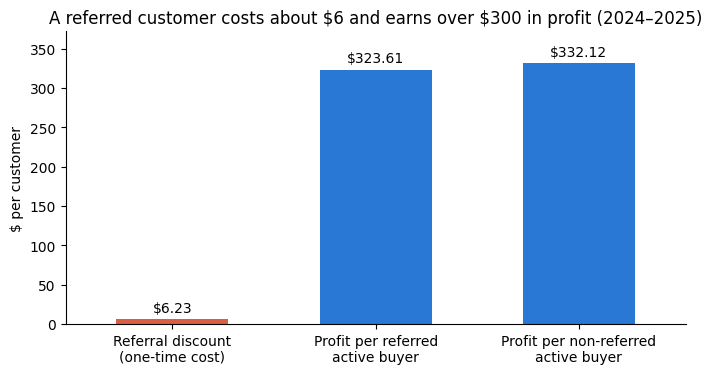

In [7]:
values = pd.Series({
    "Referral discount\n(one-time cost)": ref.referral_discount.mean(),
    "Profit per referred\nactive buyer": cohorts.loc["Referred", "profit_per_active_buyer"],
    "Profit per non-referred\nactive buyer": cohorts.loc["Not referred", "profit_per_active_buyer"],
})
ax = values.plot.bar(figsize=(8, 3.8), width=0.55, rot=0, color=["#d95f43", "#2a78d6", "#2a78d6"])
ax.bar_label(ax.containers[0], fmt="${:,.2f}", padding=3)
ax.set(title="A referred customer costs about \\$6 and earns over \\$300 in profit (2024–2025)",
       ylabel="$ per customer")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.12)
plt.show()

## 7. Conclusion

**The referral program cost \$21,325 in net revenue over two years, about \$6 per referred customer. Keep it.**

- **Revenue lost:** \$22,189 in discounts on 3,563 first orders, less \$863 recovered as extra shipping.
- **Referred customers are as valuable as others:** \$324 vs \$332 profit per active buyer, with similar activity and order size.
- **\$6 buys a customer worth over \$300 in profit**, which makes referrals likely cheaper than any paid channel (there's no marketing spend data to confirm this).

**Limits**
- "First order" means the first order in 2024–2025; most referred buyers signed up earlier, so the true cost in this window may be lower.
- The data can't show whether referred customers would have joined anyway.